In [14]:
# Dataset Overview

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Shape: (398, 25)

Dataset Information:
<class 'pandas.DataFrame'>
Index: 398 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     389 non-null    float64
 1   bp      386 non-null    float64
 2   sg      351 non-null    float64
 3   al      352 non-null    float64
 4   su      349 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      333 non-null    str    
 7   pcc     394 non-null    str    
 8   ba      394 non-null    str    
 9   bgr     355 non-null    float64
 10  bu      379 non-null    float64
 11  sc      381 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    346 non-null    float64
 15  pcv     328 non-null    float64
 16  wbcc    293 non-null    float64
 17  rbcc    268 non-null    float64
 18  htn     396 non-null    str    
 19  dm      396 non-null    str    
 20  cad     396 non-null    str    
 21  appet   

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd



Statistical Summary:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
count,389.000000,386.000000,351.000000,352.000000,349.000000,248,333,394,394,355.000000,...,328.000000,293.000000,268.000000,396,396,396,397,397,397,398
unique,NaN,NaN,NaN,NaN,NaN,2,2,2,2,NaN,...,NaN,NaN,NaN,2,2,2,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,normal,normal,notpresent,notpresent,NaN,...,NaN,NaN,NaN,no,no,no,good,no,no,ckd
freq,NaN,NaN,NaN,NaN,NaN,201,258,353,372,NaN,...,NaN,NaN,NaN,250,261,362,315,322,337,248
mean,51.516710,76.450777,1.017436,1.014205,0.432665,NaN,NaN,NaN,NaN,147.749296,...,38.844512,8411.262799,4.702612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,17.153427,13.697811,0.005718,1.351299,1.077016,NaN,NaN,NaN,NaN,79.207920,...,8.974492,2948.190084,1.024180,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,2.000000,50.000000,1.005000,0.000000,0.000000,NaN,NaN,NaN,NaN,22.000000,...,9.000000,2200.000000,2.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,42.000000,70.000000,1.010000,0.000000,0.000000,NaN,NaN,NaN,NaN,99.000000,...,32.000000,6500.000000,3.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,55.000000,80.000000,1.020000,0.000000,0.000000,NaN,NaN,NaN,NaN,121.000000,...,40.000000,8000.000000,4.800000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,65.000000,80.000000,1.020000,2.000000,0.000000,NaN,NaN,NaN,NaN,162.500000,...,45.000000,9800.000000,5.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


age        9
bp        12
sg        47
al        46
su        49
rbc      150
pc        65
pcc        4
ba         4
bgr       43
bu        19
sc        17
sod       85
pot       86
hemo      52
pcv       70
wbcc     105
rbcc     130
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

In [18]:
# Data Cleaning

# Data Cleaning

df = df.apply(
    lambda column: column.str.strip() if column.dtype == "object" else column
)

df = df.replace("?", np.nan)

numerical_columns = [
    "age", "bp", "sg", "al", "su", "bgr",
    "bu", "sc", "sod", "pot", "hemo",
    "pcv", "wbcc", "rbcc"
]

categorical_columns = [
    "rbc", "pc", "pcc", "ba", "htn",
    "dm", "cad", "appet", "pe", "ane"
]

for column in numerical_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

target_column = df.columns[-1]

df[target_column] = (
    df[target_column].astype(str).str.strip().str.lower()
)

print("Data cleaning completed!")

print("\nNumerical Data Types:")
print(df[numerical_columns].dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Data cleaning completed!

Numerical Data Types:
age     float64
bp      float64
sg      float64
al      float64
su      float64
bgr     float64
bu      float64
sc      float64
sod     float64
pot     float64
hemo    float64
pcv     float64
wbcc    float64
rbcc    float64
dtype: object

Missing Values:
age        9
bp        12
sg        47
al        46
su        49
rbc      150
pc        65
pcc        4
ba         4
bgr       43
bu        19
sc        17
sod       85
pot       86
hemo      52
pcv       70
wbcc     105
rbcc     130
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64


In [ ]:
# Data Cleaning

# Remove unwanted spaces
df = df.apply(lambda column: column.str.strip())

# Replace missing-value symbols
df = df.replace("?", np.nan)

# Numerical columns
numerical_columns = [
    "age", "bp", "sg", "al", "su", "bgr",
    "bu", "sc", "sod", "pot", "hemo",
    "pcv", "wbcc", "rbcc"
]

# Categorical columns
categorical_columns = [
    "rbc", "pc", "pcc", "ba", "htn",
    "dm", "cad", "appet", "pe", "ane"
]

# Convert numerical columns to numeric data types
for column in numerical_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Clean target column
target_column = df.columns[-1]

df[target_column] = (
    df[target_column]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Data cleaning completed!")
print("\nNumerical Data Types:")
print(df[numerical_columns].dtypes)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Data cleaning completed!

Numerical Data Types:
age     float64
bp      float64
sg      float64
al      float64
su      float64
bgr     float64
bu      float64
sc      float64
sod     float64
pot     float64
hemo    float64
pcv     float64
wbcc    float64
rbcc    float64
dtype: object

Missing Values After Cleaning:
age        9
bp        12
sg        47
al        46
su        51
rbc      150
pc        65
pcc        4
ba         5
bgr       43
bu        19
sc        19
sod       87
pot       86
hemo      53
pcv       71
wbcc     106
rbcc     132
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64


,Missing Values,Missing Percentage
rbc,150,37.50
rbcc,132,33.00
wbcc,106,26.50
sod,87,21.75
pot,86,21.50
pcv,71,17.75
pc,65,16.25
hemo,53,13.25
su,51,12.75
sg,47,11.75


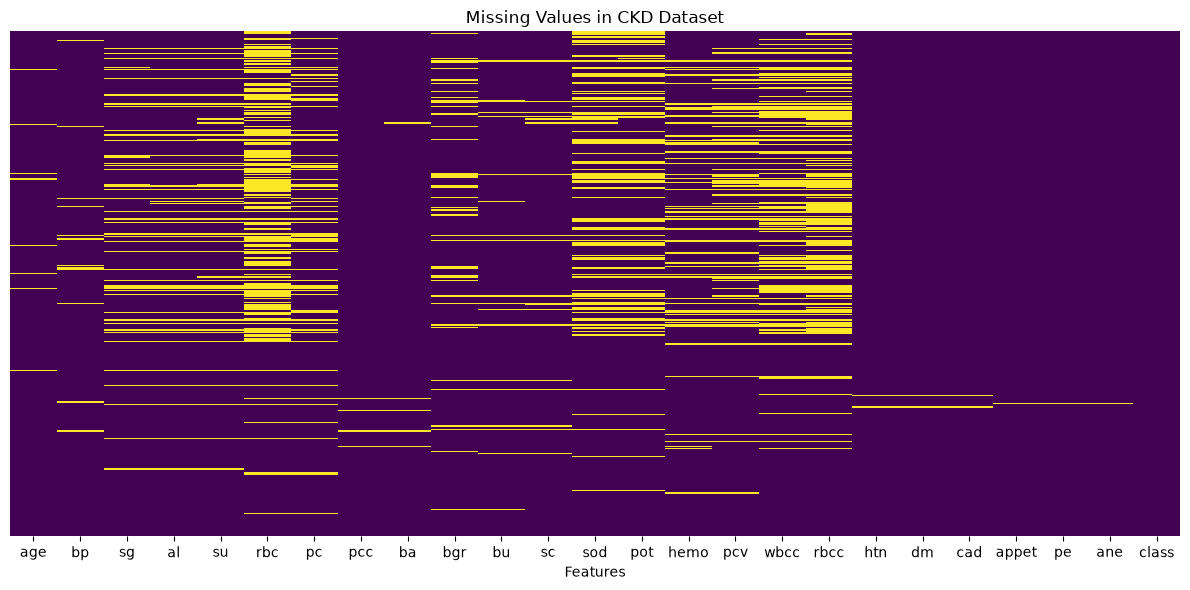

In [ ]:
# Missing Values Analysis

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

# Visualize Missing Values
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in CKD Dataset")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
# Load CKD Dataset and Handle Extra ID Column

import csv
import pandas as pd
import numpy as np
from pathlib import Path

dataset_path = Path("dataset/chronic_kidney_disease.arff")

if not dataset_path.exists():
    dataset_path = Path("../dataset/chronic_kidney_disease.arff")

attributes = []
data_rows = []

with open(dataset_path, "r", encoding="utf-8") as file:
    reading_data = False

    for line in file:
        line = line.strip()

        if not line or line.startswith("%"):
            continue

        if line.lower().startswith("@attribute"):
            parts = line.split(maxsplit=2)
            attributes.append(parts[1].strip("'\""))

        elif line.lower().startswith("@data"):
            reading_data = True
            continue

        elif reading_data:
            row = next(csv.reader([line]))

            # Remove extra ID column if present
            if len(row) == len(attributes) + 1:
                row = row[1:]

            if len(row) == len(attributes):
                data_rows.append(row)
            else:
                print("Skipped malformed row:", len(row))

df = pd.DataFrame(data_rows, columns=attributes)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset Shape: (400, 25)

Column Names:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.020,1,0,?,normal,notpresent,notpresent,121,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7,50,1.020,4,0,?,normal,notpresent,notpresent,?,...,38,6000,?,no,no,no,good,no,no,ckd
2,62,80,1.010,2,3,normal,normal,notpresent,notpresent,423,...,31,7500,?,no,yes,no,poor,no,yes,ckd
3,48,70,1.005,4,0,normal,abnormal,present,notpresent,117,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51,80,1.010,2,0,normal,normal,notpresent,notpresent,106,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
# Feature Selection and Target Separation

# Separate input features and target variable
X = df.drop("class", axis=1)
y = df["class"]

# Display features and target
print("Feature Data (X) Shape:", X.shape)
print("Target Data (y) Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.value_counts())

Feature Data (X) Shape: (400, 24)
Target Data (y) Shape: (400,)

Input Features:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

Target Classes:
class
ckd       248
notckd    150
            2
Name: count, dtype: int64


In [ ]:
# Remove Missing Target Values

df["class"] = df["class"].astype(str).str.strip().str.lower()

df = df[df["class"].isin(["ckd", "notckd"])].copy()

# Separate Features and Target
X = df.drop("class", axis=1)
y = df["class"]

print("Cleaned Dataset Shape:", df.shape)
print("Feature Data (X) Shape:", X.shape)
print("Target Data (y) Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Cleaned Dataset Shape: (398, 25)
Feature Data (X) Shape: (398, 24)
Target Data (y) Shape: (398,)

Target Distribution:
class
ckd       248
notckd    150
Name: count, dtype: int64


In [ ]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (318, 24)
Testing Data Shape: (80, 24)

Training Target Distribution:
class
ckd       198
notckd    120
Name: count, dtype: int64

Testing Target Distribution:
class
ckd       50
notckd    30
Name: count, dtype: int64


## Data Preprocessing

Data preprocessing is an important step in machine learning. It converts raw data into a suitable format for model training.

The following preprocessing techniques are used:

- **Numerical Missing Value Imputation:** Median
- **Categorical Missing Value Imputation:** Most Frequent Value (Mode)
- **Numerical Feature Scaling:** StandardScaler
- **Categorical Feature Encoding:** One-Hot Encoding

These techniques help handle missing values and convert categorical data into numerical format for the machine learning model.

Class Distribution:
class
ckd       248
notckd    150
            2
Name: count, dtype: int64

Class Percentage:
class
ckd       62.0
notckd    37.5
           0.5
Name: count, dtype: float64


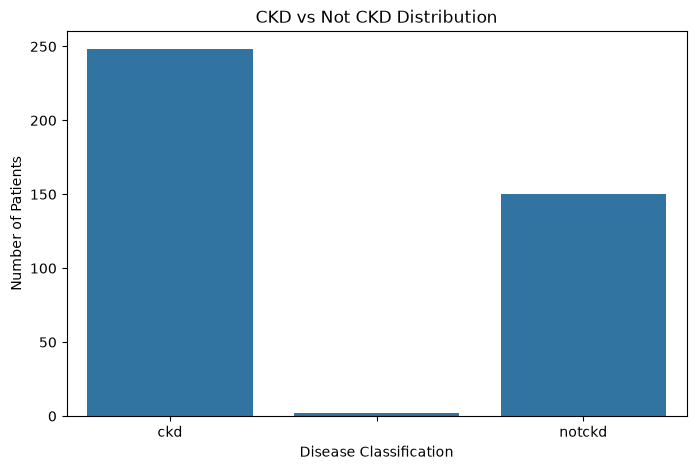

In [ ]:
# Target Class Distribution

target_column = df.columns[-1]

class_counts = df[target_column].value_counts()

print("Class Distribution:")
print(class_counts)

print("\nClass Percentage:")
print((class_counts / len(df) * 100).round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=target_column)

plt.title("CKD vs Not CKD Distribution")
plt.xlabel("Disease Classification")
plt.ylabel("Number of Patients")

plt.show()

## Model Training

Random Forest Classifier is used to predict Chronic Kidney Disease (CKD).

Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce a reliable prediction.

### Model Configuration

- Algorithm: Random Forest Classifier
- Number of Estimators: 100
- Random State: 42
- Training Data: 80%
- Testing Data: 20%

The model is trained using the preprocessed clinical data to classify patients as CKD or Not CKD.

In [ ]:
# Check target labels

target_column = df.columns[-1]

print("Original target values:")
print(df[target_column].value_counts(dropna=False))

# Clean target labels
df[target_column] = (
    df[target_column]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Remove invalid target records
df = df[df[target_column].isin(["ckd", "notckd"])].copy()

print("\nCleaned target distribution:")
print(df[target_column].value_counts())

print("\nUpdated Dataset Shape:", df.shape)

Original target values:
class
ckd       248
notckd    150
            2
Name: count, dtype: int64

Cleaned target distribution:
class
ckd       248
notckd    150
Name: count, dtype: int64

Updated Dataset Shape: (398, 25)


## Model Evaluation

The trained Random Forest model is evaluated using the test dataset.

The following evaluation metrics are used:

- Accuracy
- Precision
- Recall
- F1-Score

These metrics help measure the model's prediction performance and reliability.

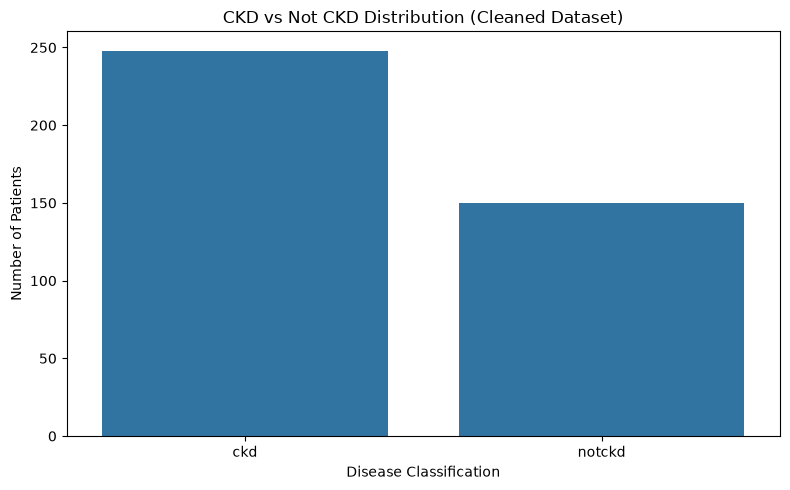

In [ ]:
# Visualize cleaned target distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="class", order=["ckd", "notckd"])

plt.title("CKD vs Not CKD Distribution (Cleaned Dataset)")
plt.xlabel("Disease Classification")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

## Model Evaluation Results

The Random Forest model was evaluated using 80 test samples.

The model achieved the following results:

| Evaluation Metric | Score |
|---|---|
| Accuracy | 100% |
| Precision | 100% |
| Recall | 100% |
| F1-Score | 100% |

The model correctly classified all 80 test samples in the previous evaluation.

These results indicate excellent performance on this particular test split. However, further validation using different datasets is required to assess generalization.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


## Confusion Matrix

A confusion matrix is used to evaluate the classification performance of a machine learning model.

It compares the actual class labels with the predicted class labels.

- True Positive (TP): Correctly predicted CKD cases.
- True Negative (TN): Correctly predicted Not CKD cases.
- False Positive (FP): Not CKD cases incorrectly predicted as CKD.
- False Negative (FN): CKD cases incorrectly predicted as Not CKD.

The confusion matrix helps identify the types of prediction errors made by the model.

,Missing Values,Missing Percentage
rbc,150,37.69
rbcc,130,32.66
wbcc,105,26.38
pot,86,21.61
sod,85,21.36
pcv,70,17.59
pc,65,16.33
hemo,52,13.07
su,49,12.31
sg,47,11.81


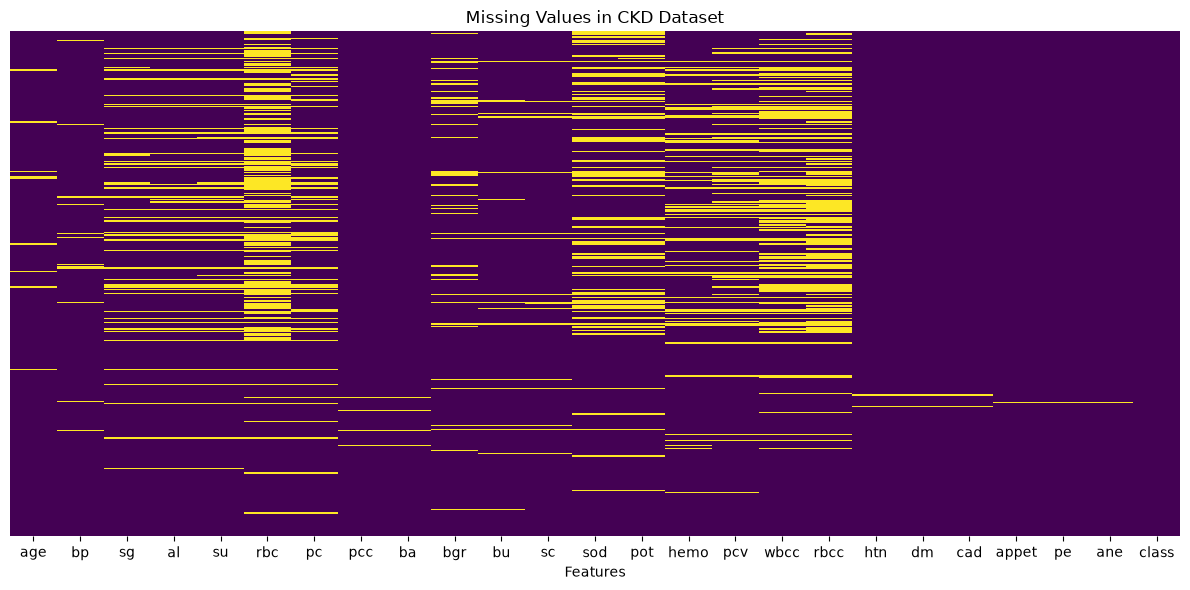

In [16]:
# Missing Values Analysis

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

# Visualize missing values
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in CKD Dataset")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

Feature importance identifies the input features that contribute most to the machine learning model's predictions.

The Random Forest algorithm calculates the importance of each feature based on its contribution to the model.

This analysis helps understand which clinical parameters have a greater influence on CKD prediction.

The feature importance values are visualized using a bar chart.

In [ ]:
# Load CKD Dataset

import csv
import pandas as pd
import numpy as np
from pathlib import Path

dataset_path = Path("../dataset/chronic_kidney_disease.arff")

if not dataset_path.exists():
    dataset_path = Path("dataset/chronic_kidney_disease.arff")

attributes = []
data_rows = []

with open(dataset_path, "r", encoding="utf-8") as file:
    reading_data = False

    for line in file:
        line = line.strip()

        if not line or line.startswith("%"):
            continue

        if line.lower().startswith("@attribute"):
            parts = line.split(maxsplit=2)
            attributes.append(parts[1].strip("'\""))

        elif line.lower().startswith("@data"):
            reading_data = True
            continue

        elif reading_data:
            row = next(csv.reader([line]))

            if len(row) == len(attributes) + 1:
                row = row[1:]

            if len(row) == len(attributes):
                data_rows.append(row)

df = pd.DataFrame(data_rows, columns=attributes)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.020,1,0,?,normal,notpresent,notpresent,121,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7,50,1.020,4,0,?,normal,notpresent,notpresent,?,...,38,6000,?,no,no,no,good,no,no,ckd
2,62,80,1.010,2,3,normal,normal,notpresent,notpresent,423,...,31,7500,?,no,yes,no,poor,no,yes,ckd
3,48,70,1.005,4,0,normal,abnormal,present,notpresent,117,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51,80,1.010,2,0,normal,normal,notpresent,notpresent,106,...,35,7300,4.6,no,no,no,good,no,no,ckd


## Result and Discussion

The Random Forest model was used to predict Chronic Kidney Disease using clinical parameters.

The model achieved 100% accuracy on the test dataset containing 80 samples.

The evaluation results showed that the model correctly classified all test samples in this particular split.

The results demonstrate the potential of machine learning for CKD prediction. However, further validation with larger and independent datasets is necessary.

# Chronic Kidney Disease Prediction Using Machine Learning

## Project Introduction

Chronic Kidney Disease (CKD) is a health condition that affects kidney function. Early identification of CKD risk is important for timely medical evaluation.

This project uses Machine Learning to predict the possibility of Chronic Kidney Disease based on clinical parameters.

**Algorithm Used:** Random Forest Classifier

**Dataset:** UCI Chronic Kidney Disease Dataset

**Objective:** To develop a machine learning model that classifies patient data into CKD or Not CKD.

## Conclusion

This project developed a machine learning system for Chronic Kidney Disease prediction using the UCI CKD dataset.

The Random Forest Classifier was used to classify patient records into CKD and Not CKD categories.

The project demonstrates how machine learning can support early identification of CKD risk. The model is intended for educational and decision-support purposes and cannot replace professional medical diagnosis.

## References

1. UCI Machine Learning Repository – Chronic Kidney Disease Dataset  
   https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease

2. Scikit-learn Documentation – Machine Learning Library  
   https://scikit-learn.org/

3. Pandas Documentation – Data Analysis Library  
   https://pandas.pydata.org/docs/

4. Flask Documentation – Web Application Framework  
   https://flask.palletsprojects.com/